# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhammad Farid Wijdan | 5054251042 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, classification_report
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11

print("torch:", torch.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("sklearn:", __import__("sklearn").__version__)
print("device:", "cuda" if torch.cuda.is_available() else "cpu")

torch: 2.15.0
numpy: 2.5.3
pandas: 3.0.5
sklearn: 1.9.1
device: cpu


In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv("Churn_Modelling.csv")
print(f"Bentuk dataset: {df.shape} (baris, kolom)")
print(f"Kolom: {list(df.columns)}")
print()
print("5 baris pertama:")
display(df.head())
print()
print("Info dataset:")
print(df.info())
print()
print("Tipe data:")
print(df.dtypes)
print()
print("Statistik deskriptif:")
display(df.describe().T)
print()
print("Jumlah missing value per kolom:")
print(df.isna().sum())
print(f"Total missing: {df.isna().sum().sum()}")

Bentuk dataset: (10000, 14) (baris, kolom)
Kolom: ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

5 baris pertama:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Info dataset:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB
None

Tipe data:
RowNumber            int64
CustomerId           int64
Surname                

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48



Jumlah missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Total missing: 0


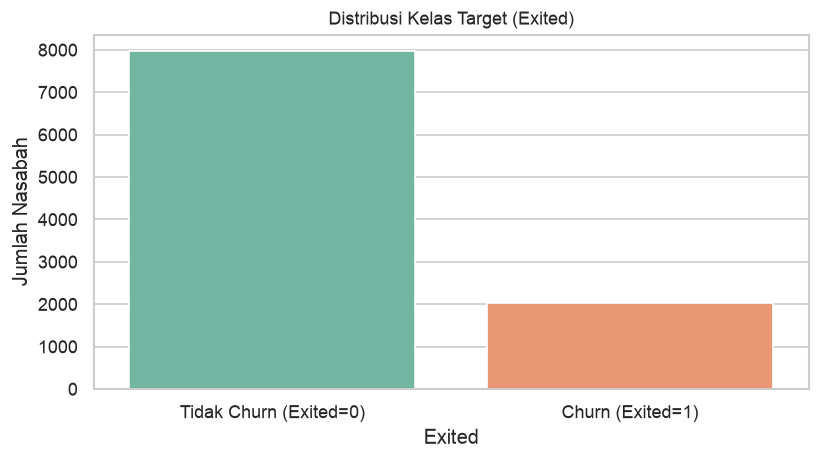

Exited
0    7963
1    2037
Name: count, dtype: int64

Exited=0: 7963 (79.63%)
Exited=1: 2037 (20.37%)
Rasio kelas mayoritas : minoritas = 3.91 : 1
Dataset ini imbalanced: kelas churn hanya sekitar 1/5 dari data, sehingga model yang hanya menebak kelas mayoritas pun sudah terlihat akurat.


In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

plt.figure(figsize=(7, 4))
sns.countplot(x="Exited", data=df, hue="Exited", palette="Set2", legend=False)
plt.xticks([0, 1], ["Tidak Churn (Exited=0)", "Churn (Exited=1)"])
plt.title("Distribusi Kelas Target (Exited)")
plt.xlabel("Exited")
plt.ylabel("Jumlah Nasabah")
plt.tight_layout()
plt.show()

counts = df["Exited"].value_counts().sort_index()
print(counts)
print()
for k, v in counts.items():
    print(f"Exited={k}: {v} ({v/len(df)*100:.2f}%)")
ratio = counts[0] / counts[1]
print(f"Rasio kelas mayoritas : minoritas = {ratio:.2f} : 1")
print("Dataset ini imbalanced: kelas churn hanya sekitar 1/5 dari data, sehingga model yang hanya menebak kelas mayoritas pun sudah terlihat akurat.")


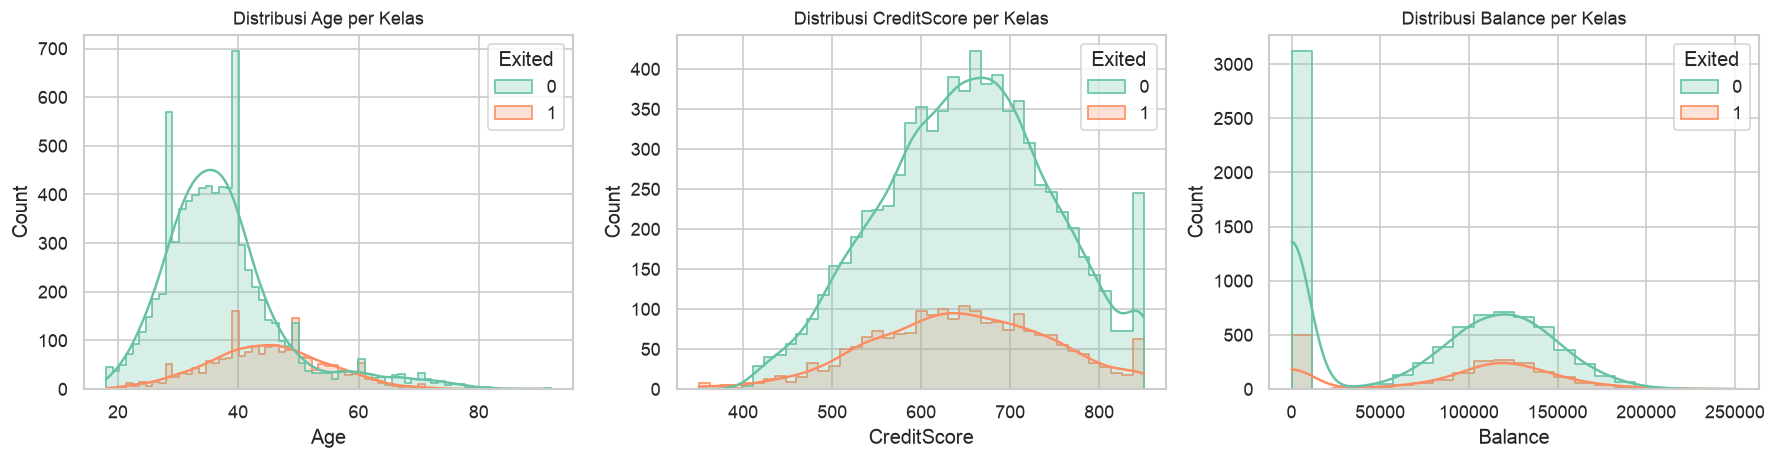

Rata-rata per kelas (median juga ditampilkan karena Balance sangat miring):
         Age  CreditScore    Balance
Exited                              
0       36.0        653.0   92072.68
1       45.0        646.0  109349.29

              Age  CreditScore       Balance
Exited                                      
0       37.408389   651.853196  72745.296779
1       44.837997   645.351497  91108.539337

Observasi awal:
- Nasabah churn cenderung lebih tua (median Age lebih tinggi).
- Balance sangat miring ke kanan dan banyak bernilai 0 (nasabah tanpa simpanan), jadi scaling sangat penting untuk ANN.


In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "CreditScore", "Balance"]):
    sns.histplot(data=df, x=col, hue="Exited", kde=True, ax=ax, palette="Set2", element="step")
    ax.set_title(f"Distribusi {col} per Kelas")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

print("Rata-rata per kelas (median juga ditampilkan karena Balance sangat miring):")
print(df.groupby("Exited")[["Age", "CreditScore", "Balance"]].median())
print()
print(df.groupby("Exited")[["Age", "CreditScore", "Balance"]].mean())
print()
print("Observasi awal:")
print("- Nasabah churn cenderung lebih tua (median Age lebih tinggi).")
print("- Balance sangat miring ke kanan dan banyak bernilai 0 (nasabah tanpa simpanan), jadi scaling sangat penting untuk ANN.")

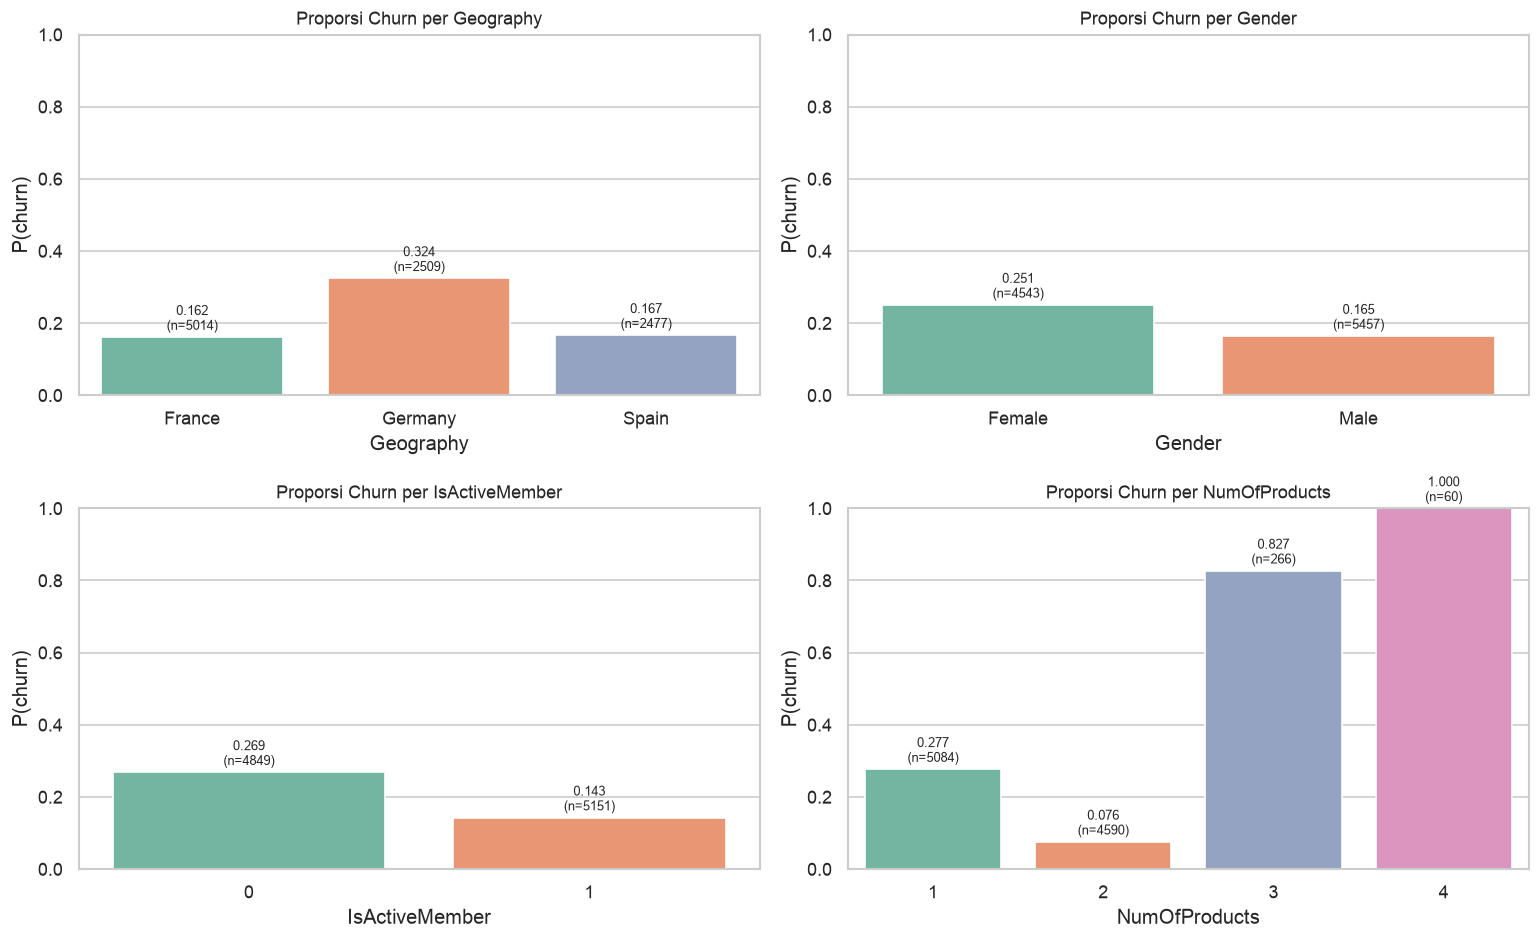

--- Geography ---
               mean  count
Geography                 
France     0.161548   5014
Germany    0.324432   2509
Spain      0.166734   2477

--- Gender ---
            mean  count
Gender                 
Female  0.250715   4543
Male    0.164559   5457

--- IsActiveMember ---
                    mean  count
IsActiveMember                 
0               0.268509   4849
1               0.142691   5151

--- NumOfProducts ---
                   mean  count
NumOfProducts                 
1              0.277144   5084
2              0.075817   4590
3              0.827068    266
4              1.000000     60



In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]):
    rate = df.groupby(col)["Exited"].mean().reindex(sorted(df[col].unique(), key=str))
    count = df.groupby(col)["Exited"].count().reindex(rate.index)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, hue=rate.index.astype(str), palette="Set2", legend=False)
    ax.set_title(f"Proporsi Churn per {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("P(churn)")
    ax.set_ylim(0, 1.0)
    for i, (cat, r) in enumerate(rate.items()):
        ax.text(i, r + 0.02, f"{r:.3f}\n(n={count[cat]})", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

for col in ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]:
    tab = df.groupby(col)["Exited"].agg(["mean", "count"])
    print(f"--- {col} ---")
    print(tab)
    print()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Dua cell kode di bawah ini melakukan EDA tambahan: (1) matriks korelasi fitur numerik + boxplot `Balance`/`Age` per kelas, dan (2) sebaran `Geography`/`Gender`/`NumOfProducts` x `Exited` beserta crosstab ternormalisasi. Temuan ditulis singkat dalam markdown setelah kedua cell tersebut.

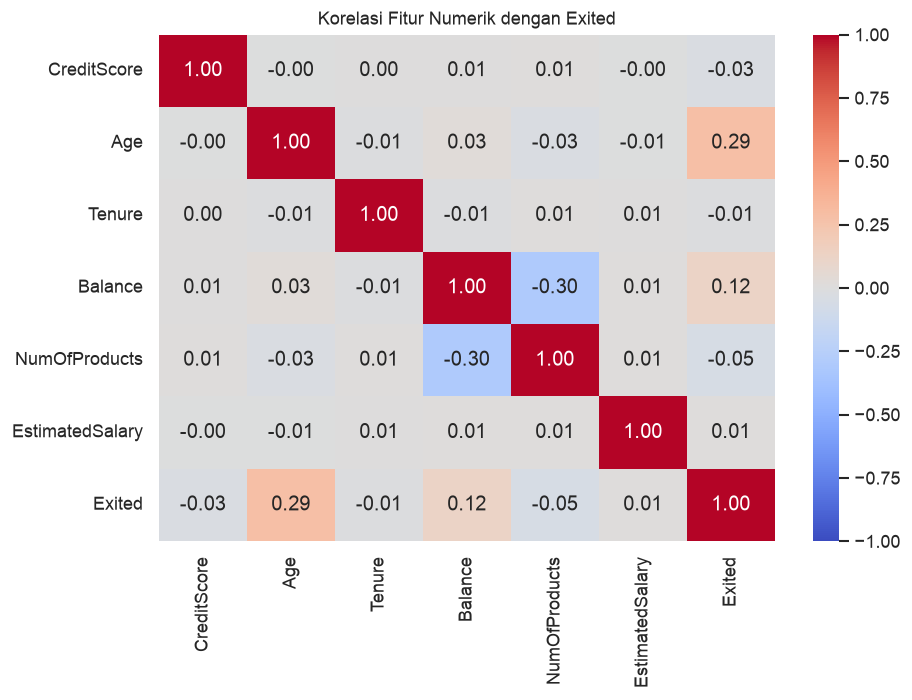

Korelasi dengan Exited (urut dari terlemah ke terkuat):
NumOfProducts     -0.047820
CreditScore       -0.027094
Tenure            -0.014001
EstimatedSalary    0.012097
Balance            0.118533
Age                0.285323

Balance == 0: 3617 baris (36.2%)
Ada 2932 surname unik untuk 10000 baris -> Surname adalah identitas string ber-cardinality tinggi, tidak informatif untuk model tabular ini.


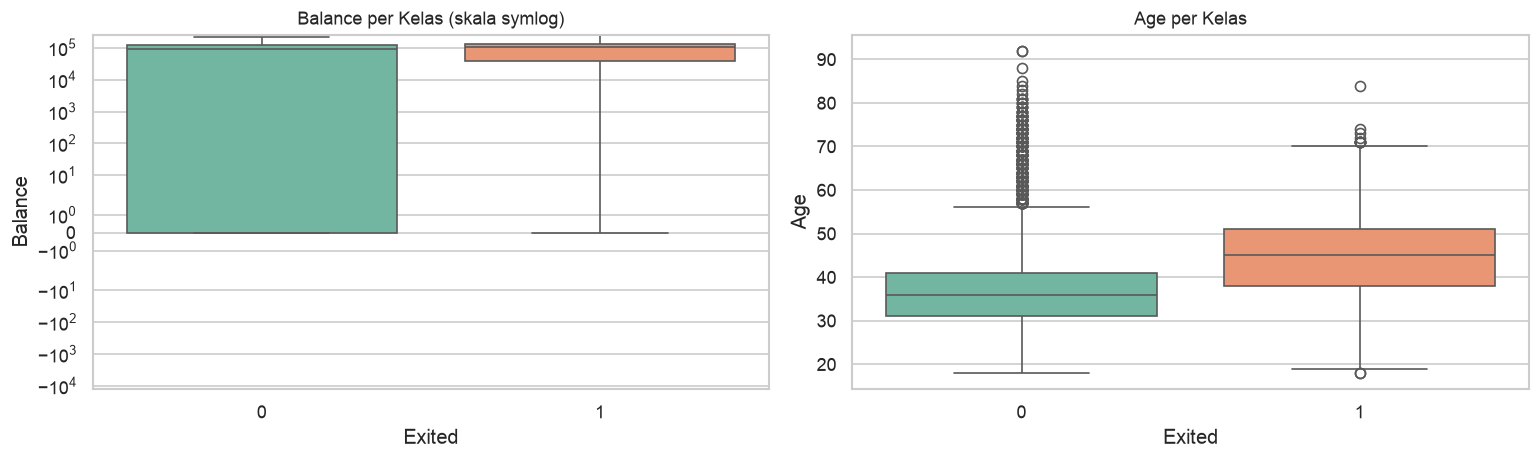

In [6]:
# Tambahan EDA: korelasi numerik dan distribusi Balance per kelas (boxplot).
# Tujuannya: melihat faktor apa yang berkorelasi dengan churn dan apakah ada outlier / pola khusus.

numeric_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary", "Exited"]
corr = df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Korelasi Fitur Numerik dengan Exited")
plt.tight_layout()
plt.show()

print("Korelasi dengan Exited (urut dari terlemah ke terkuat):")
print(corr["Exited"].drop("Exited").sort_values().to_string())
print()
print(f"Balance == 0: {(df['Balance'] == 0).sum()} baris ({(df['Balance'] == 0).mean()*100:.1f}%)")
print(f"Ada {df['Surname'].nunique()} surname unik untuk 10000 baris -> Surname adalah identitas string ber-cardinality tinggi, tidak informatif untuk model tabular ini.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="Exited", y="Balance", ax=axes[0], hue="Exited", palette="Set2", legend=False)
axes[0].set_yscale("symlog")
axes[0].set_title("Balance per Kelas (skala symlog)")
sns.boxplot(data=df, x="Exited", y="Age", ax=axes[1], hue="Exited", palette="Set2", legend=False)
axes[1].set_title("Age per Kelas")
plt.tight_layout()
plt.show()

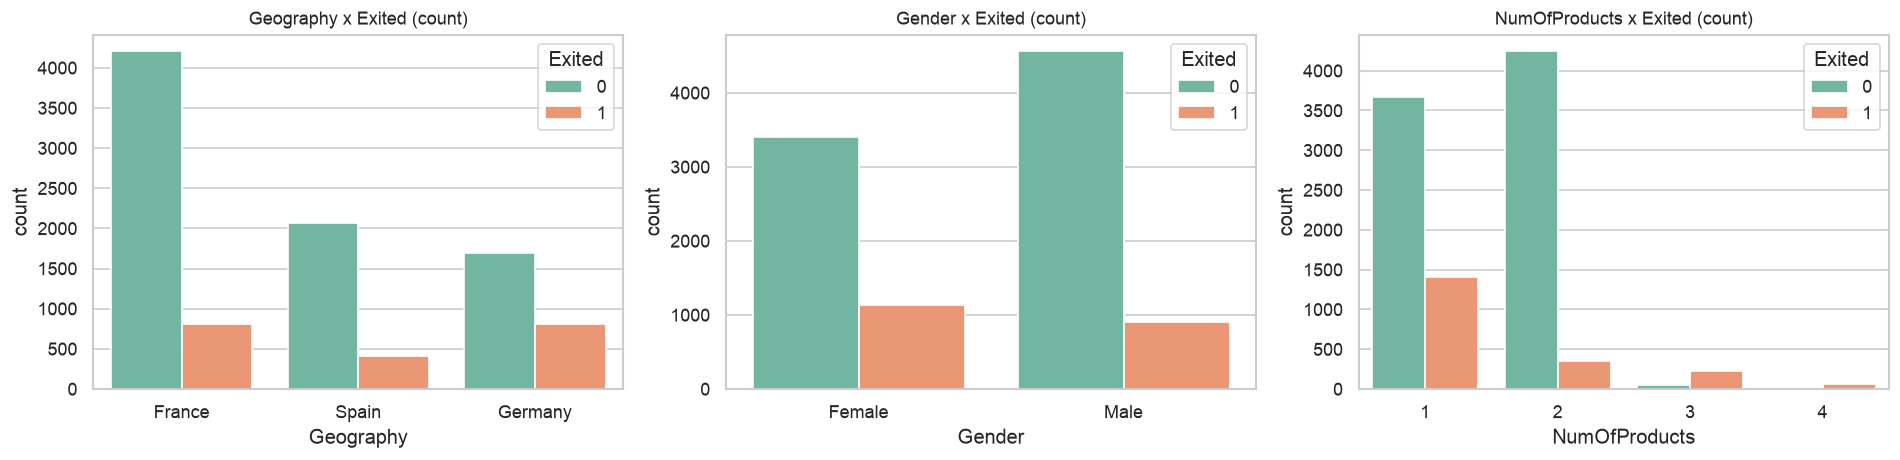

Exited         0      1
Geography              
France     0.838  0.162
Germany    0.676  0.324
Spain      0.833  0.167

Exited             0      1
NumOfProducts              
1              0.723  0.277
2              0.924  0.076
3              0.173  0.827
4              0.000  1.000

NumOfProducts=3: n=266, NumOfProducts=4: n=60
Pola NumOfProducts sangat penting: proporsi churn melonjak ekstrem pada 3-4 produk meski jumlahnya kecil, sehingga model harus belajar pola non-linear ini.


In [7]:
# Tambahan EDA: sebaran Geography/Gender dan pola NumOfProducts yang ekstrem.

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="Geography", hue="Exited", ax=axes[0], palette="Set2")
axes[0].set_title("Geography x Exited (count)")
sns.countplot(data=df, x="Gender", hue="Exited", ax=axes[1], palette="Set2")
axes[1].set_title("Gender x Exited (count)")
sns.countplot(data=df, x="NumOfProducts", hue="Exited", ax=axes[2], palette="Set2")
axes[2].set_title("NumOfProducts x Exited (count)")
plt.tight_layout()
plt.show()

print(pd.crosstab(df["Geography"], df["Exited"], normalize="index").round(3).to_string())
print()
print(pd.crosstab(df["NumOfProducts"], df["Exited"], normalize="index").round(3).to_string())
print()
print(f"NumOfProducts=3: n={(df['NumOfProducts']==3).sum()}, NumOfProducts=4: n={(df['NumOfProducts']==4).sum()}")
print("Pola NumOfProducts sangat penting: proporsi churn melonjak ekstrem pada 3-4 produk meski jumlahnya kecil, sehingga model harus belajar pola non-linear ini.")

### Temuan EDA Tambahan

1. **Tidak ada missing value** pada semua 14 kolom (10.000 baris). Kolom identitas (`RowNumber`, `CustomerId`, `Surname`) tidak berisi sinyal prediksi: korelasinya dengan `Exited` kecil (`RowNumber` -0.02, `CustomerId` -0.01) dan `Surname` punya cardinality sangat tinggi, sehingga ketiganya di-drop saat preprocessing.
2. **Korelasi numerik terkuat dengan churn adalah `Age` (0.29)**, lalu `Balance` (0.12). `IsActiveMember` berkorelasi negatif (-0.16) — anggota aktif lebih kecil kemungkinannya churn. `Tenure`, `HasCrCard`, `EstimatedSalary`, `CreditScore` korelasinya lemah (< 0.03), tetapi tetap dipertahankan karena ANN dapat menangkap interaksi non-linearnya.
3. **`Balance` sangat miring**: 36,2% baris bernilai 0 (nasabah tanpa saldo). Boxplot menunjukkan sebaran Balance kelas churn lebih lebar ke atas. Hal ini menegaskan pentingnya `StandardScaler` agar fitur bervariasi besar seperti `Balance` dan `EstimatedSalary` tidak mendominasi gradien ANN.
4. **Efek kategorikal besar**: churn di Germany (32,4%) hampir dua kali lipat France (16,2%) dan Spain (16,7%); perempuan churn 25,1% vs laki-laki 16,5%; anggota non-aktif churn 26,9% vs aktif 14,3%. `Geography` perlu OneHot encoding, `Gender` cukup 0/1.
5. **Pola `NumOfProducts` ekstrem**: churn hanya 7,6% pada 2 produk, tetapi naik ke 27,7% pada 1 produk, 82,7% pada 3 produk, dan 100% pada 4 produk (n kecil: 266 dan 60). Ini pola non-linear yang tidak dapat ditangkap Logistic Regression secara utuh, menjadi alasan kuat menguji ANN.
6. Distribusi `Age` pada kelas churn pergeser ke kanan (nasabah lebih tua lebih rawan churn), sehingga histogram perlu dua mode terpisah dan model perlu fitur Age yang diskala.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [8]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

drop_cols = ["RowNumber", "CustomerId", "Surname"]
# - RowNumber: hanya nomor urut baris, bukan fitur nasabah; korelasi dengan Exited ~ -0.02 (hampir nol).
# - CustomerId: identitas numerik acak untuk setiap nasabah; tidak mengandung sinyal churn.
# - Surname: nama keluarga berupa teks bebas ber-cardinality tinggi (~2500 nilai unik); ANN tabular tidak dapat memproses teks mentah dan tidak informatif untuk churn.
df_model = df.drop(columns=drop_cols)

print(f"Kolom setelah drop: {list(df_model.columns)}")
print(f"Bentuk setelah drop: {df_model.shape}")
display(df_model.head())

Kolom setelah drop: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
Bentuk setelah drop: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [9]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df_model.drop(columns=["Exited"])
y = df_model["Exited"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}")
print()
print("Distribusi kelas train:")
print(y_train.value_counts(normalize=True).sort_index().to_string())
print()
print("Distribusi kelas validasi:")
print(y_val.value_counts(normalize=True).sort_index().to_string())
print()
print("Distribusi kelas test:")
print(y_test.value_counts(normalize=True).sort_index().to_string())

X_train: (7000, 10), X_val: (1500, 10), X_test: (1500, 10)

Distribusi kelas train:
Exited
0    0.796286
1    0.203714

Distribusi kelas validasi:
Exited
0    0.796
1    0.204

Distribusi kelas test:
Exited
0    0.796667
1    0.203333


In [10]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

numeric_features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
geo_features = ["Geography"]     # nominal 3 negara -> OneHot (3 kolom)
gender_features = ["Gender"]     # biner -> 0/1 (Female=0, Male=1)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("geo", OneHotEncoder(handle_unknown="ignore", sparse_output=False), geo_features),
        ("gender", OrdinalEncoder(categories=[["Female", "Male"]]), gender_features),
    ],
    sparse_threshold=0.0,
)

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

# ColumnTransformer dapat mengembalikan sparse matrix; pastikan dense float array.
X_train_proc = np.asarray(X_train_proc, dtype=np.float64)
X_val_proc = np.asarray(X_val_proc, dtype=np.float64)
X_test_proc = np.asarray(X_test_proc, dtype=np.float64)

print("Nama fitur hasil preprocessing:")
try:
    print(preprocessor.get_feature_names_out())
except Exception as e:
    print("(tidak tersedia:", e, ")")
print(f"Bentuk X_train_proc: {X_train_proc.shape}, X_val_proc: {X_val_proc.shape}, X_test_proc: {X_test_proc.shape}")
print("Rata-rata fitur numerik pada train (setelah scaling, idealnya ~0):")
for i, name in enumerate(numeric_features):
    print(f"  {name:15s} mean={X_train_proc[:, i].mean():.4f} std={X_train_proc[:, i].std():.4f}")
print("Contoh 3 baris pertama X_train_proc:")
print(X_train_proc[:3])

Nama fitur hasil preprocessing:
['num__CreditScore' 'num__Age' 'num__Tenure' 'num__Balance'
 'num__NumOfProducts' 'num__HasCrCard' 'num__IsActiveMember'
 'num__EstimatedSalary' 'geo__Geography_France' 'geo__Geography_Germany'
 'geo__Geography_Spain' 'gender__Gender']
Bentuk X_train_proc: (7000, 12), X_val_proc: (1500, 12), X_test_proc: (1500, 12)
Rata-rata fitur numerik pada train (setelah scaling, idealnya ~0):
  CreditScore     mean=0.0000 std=1.0000
  Age             mean=0.0000 std=1.0000
  Tenure          mean=-0.0000 std=1.0000
  Balance         mean=-0.0000 std=1.0000
  NumOfProducts   mean=0.0000 std=1.0000
  HasCrCard       mean=0.0000 std=1.0000
  IsActiveMember  mean=-0.0000 std=1.0000
  EstimatedSalary mean=0.0000 std=1.0000
Contoh 3 baris pertama X_train_proc:
[[-0.57558225 -1.79667873 -0.34947397  0.31290573 -0.91248301  0.6430943
  -1.03459817  1.36251232  1.          0.          0.          1.        ]
 [ 0.39818245  2.26982524 -1.38692851 -1.22357411  0.79949262  0.643

In [11]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

X_train_t = torch.tensor(X_train_proc, dtype=torch.float32)
X_val_t = torch.tensor(X_val_proc, dtype=torch.float32)
X_test_t = torch.tensor(X_test_proc, dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

print(f"X_train_t: {X_train_t.shape}, y_train_t: {y_train_t.shape}")
print(f"X_val_t: {X_val_t.shape}, y_val_t: {y_val_t.shape}")
print(f"X_test_t: {X_test_t.shape}, y_test_t: {y_test_t.shape}")
print(f"Input dimension (jumlah fitur): {X_train_t.shape[1]}")

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
print(f"Jumlah batch per epoch (train): {len(train_loader)}")
xb, yb = next(iter(train_loader))
print(f"Contoh batch: xb={xb.shape}, yb={yb.shape}")

X_train_t: torch.Size([7000, 12]), y_train_t: torch.Size([7000, 1])
X_val_t: torch.Size([1500, 12]), y_val_t: torch.Size([1500, 1])
X_test_t: torch.Size([1500, 12]), y_test_t: torch.Size([1500, 1])
Input dimension (jumlah fitur): 12
Jumlah batch per epoch (train): 219
Contoh batch: xb=torch.Size([32, 12]), yb=torch.Size([32, 1])


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [12]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_proc, y_train)

y_pred_lr = lr_model.predict(X_test_proc)
y_proba_lr = lr_model.predict_proba(X_test_proc)[:, 1]

print("Koefisien Logistic Regression:")
for name, coef in sorted(zip(preprocessor.get_feature_names_out(), lr_model.coef_[0]), key=lambda x: abs(x[1]), reverse=True):
    print(f"  {name:35s} coef={coef:.4f}")
print(f"Intercept: {lr_model.intercept_[0]:.4f}")
print()
print(f"Accuracy LR: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision LR: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall LR: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1 LR: {f1_score(y_test, y_pred_lr):.4f}")
print("Ini baseline linear: performa ANN hanya layak jika mengalahkan angka-angka ini.")

Koefisien Logistic Regression:
  num__Age                            coef=0.7050
  geo__Geography_France               coef=-0.5958
  geo__Geography_Spain                coef=-0.5721
  num__IsActiveMember                 coef=-0.5060
  gender__Gender                      coef=-0.4975
  geo__Geography_Germany              coef=0.2156
  num__Balance                        coef=0.1519
  num__CreditScore                    coef=-0.1010
  num__EstimatedSalary                coef=0.0507
  num__NumOfProducts                  coef=-0.0302
  num__HasCrCard                      coef=-0.0154
  num__Tenure                         coef=0.0037
Intercept: -0.9647

Accuracy LR: 0.8153
Precision LR: 0.6458
Recall LR: 0.2033
F1 LR: 0.3092
Ini baseline linear: performa ANN hanya layak jika mengalahkan angka-angka ini.


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [13]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANNSimple(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)

input_dim = X_train_t.shape[1]
model_ann_simple = ANNSimple(input_dim)
print(model_ann_simple)
print(f"Jumlah parameter ANN sederhana: {sum(p.numel() for p in model_ann_simple.parameters())}")
print(f"Arsitektur: Input ({input_dim}) -> Linear(16) -> ReLU -> Linear(1) logit (tanpa Sigmoid di model; sigmoid dipakai saat prediksi)")

ANNSimple(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter ANN sederhana: 225
Arsitektur: Input (12) -> Linear(16) -> ReLU -> Linear(1) logit (tanpa Sigmoid di model; sigmoid dipakai saat prediksi)


In [14]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

EPOCHS_CHURN = 20
LR_CHURN = 1e-3
BATCH_CHURN = 32  # sudah dipakai saat membuat train_loader di sel preprocessing

def train_ann(model, train_loader, X_train_t, y_train_t, X_val_t, y_val_t, epochs=EPOCHS_CHURN, lr=LR_CHURN, pos_weight=None):
    """Latih ANN biner. pos_weight (scalar tensor) opsional untuk menangani imbalance.
    Loss validasi selalu dihitung dengan BCE biasa (tanpa pos_weight) agar learning curve antar-model sebanding."""
    if pos_weight is not None:
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
    else:
        criterion = nn.BCEWithLogitsLoss()
    val_criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        tl_sum, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            tl_sum += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            correct += (preds == yb).sum().item()
            total += xb.size(0)
        train_loss = tl_sum / total
        train_acc = correct / total
        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_t)
            val_loss = val_criterion(val_logits, y_val_t).item()
            val_acc = ((torch.sigmoid(val_logits) >= 0.5).float() == y_val_t).float().mean().item()
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f"Epoch {epoch:2d}/{epochs} | train_loss={train_loss:.4f} acc={train_acc:.4f} | val_loss={val_loss:.4f} acc={val_acc:.4f}")
    return model, history

model_ann_simple, history_ann_simple = train_ann(model_ann_simple, train_loader, X_train_t, y_train_t, X_val_t, y_val_t)
print(f"Selesai. Final val_loss={history_ann_simple['val_loss'][-1]:.4f}, val_acc={history_ann_simple['val_acc'][-1]:.4f}")

Epoch  1/20 | train_loss=0.5244 acc=0.7941 | val_loss=0.4521 acc=0.7960


Epoch  5/20 | train_loss=0.3907 acc=0.8389 | val_loss=0.3689 acc=0.8433


Epoch 10/20 | train_loss=0.3526 acc=0.8531 | val_loss=0.3359 acc=0.8567


Epoch 15/20 | train_loss=0.3472 acc=0.8567 | val_loss=0.3304 acc=0.8593


Epoch 20/20 | train_loss=0.3445 acc=0.8584 | val_loss=0.3284 acc=0.8600
Selesai. Final val_loss=0.3284, val_acc=0.8600


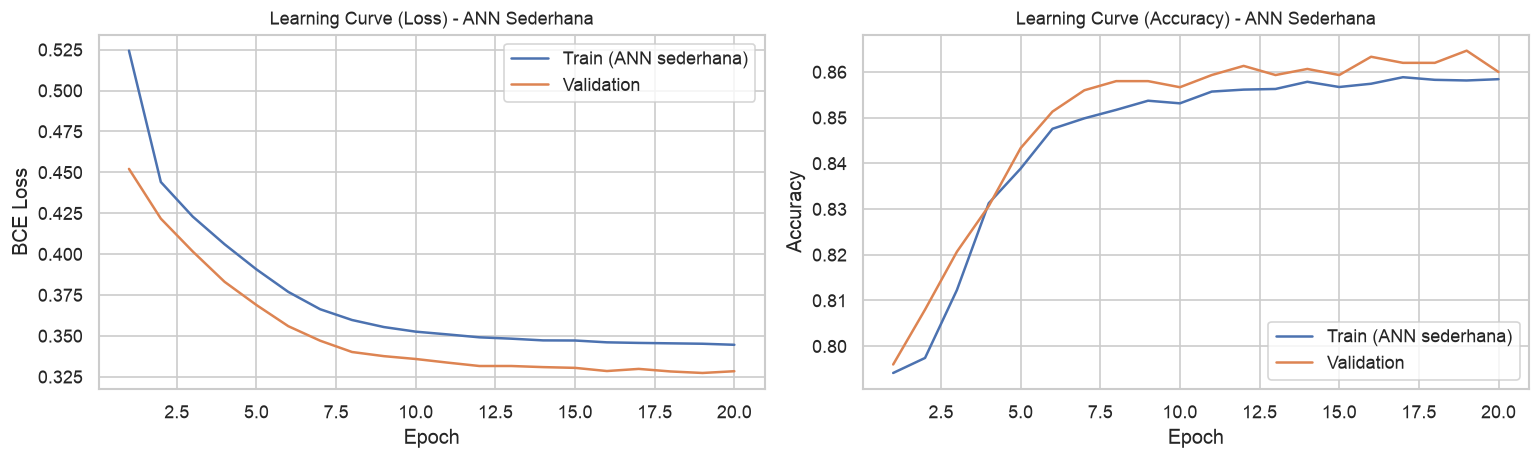

In [15]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs_range = range(1, len(history_ann_simple["train_loss"]) + 1)
axes[0].plot(epochs_range, history_ann_simple["train_loss"], label="Train (ANN sederhana)")
axes[0].plot(epochs_range, history_ann_simple["val_loss"], label="Validation")
axes[0].set_title("Learning Curve (Loss) - ANN Sederhana")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].legend()
axes[1].plot(epochs_range, history_ann_simple["train_acc"], label="Train (ANN sederhana)")
axes[1].plot(epochs_range, history_ann_simple["val_acc"], label="Validation")
axes[1].set_title("Learning Curve (Accuracy) - ANN Sederhana")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

In [16]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

model_ann_simple.eval()
with torch.no_grad():
    logits_test = model_ann_simple(X_test_t)
    y_proba_ann_simple = torch.sigmoid(logits_test).cpu().numpy().flatten()
y_pred_ann_simple = (y_proba_ann_simple >= 0.5).astype(int)

print("Contoh probabilitas (5 pertama):", y_proba_ann_simple[:5].round(4))
print(f"Accuracy ANN sederhana: {accuracy_score(y_test, y_pred_ann_simple):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_ann_simple):.4f}, Recall: {recall_score(y_test, y_pred_ann_simple):.4f}, F1: {f1_score(y_test, y_pred_ann_simple):.4f}")

Contoh probabilitas (5 pertama): [0.1701 0.0174 0.0683 0.0862 0.1495]
Accuracy ANN sederhana: 0.8647
Precision: 0.7713, Recall: 0.4754, F1: 0.5882


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [17]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class ANNDropout(nn.Module):
    def __init__(self, input_dim, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x)

model_ann_dropout = ANNDropout(input_dim, p=0.3)
print(model_ann_dropout)
print(f"Jumlah parameter ANN Dropout: {sum(p.numel() for p in model_ann_dropout.parameters())}")
print("Arsitektur: Input -> Linear(64) -> ReLU -> Dropout(0.3) -> Linear(32) -> ReLU -> Dropout(0.3) -> Linear(1)")
print("Fungsi Dropout: menonaktifkan neuron acak 30% saat training agar model tidak mengandalkan satu jalur tertentu (mengurangi overfitting).")

ANNDropout(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Jumlah parameter ANN Dropout: 2945
Arsitektur: Input -> Linear(64) -> ReLU -> Dropout(0.3) -> Linear(32) -> ReLU -> Dropout(0.3) -> Linear(1)
Fungsi Dropout: menonaktifkan neuron acak 30% saat training agar model tidak mengandalkan satu jalur tertentu (mengurangi overfitting).


Epoch  1/20 | train_loss=0.4901 acc=0.7937 | val_loss=0.4174 acc=0.8193


Epoch  5/20 | train_loss=0.3776 acc=0.8451 | val_loss=0.3446 acc=0.8500


Epoch 10/20 | train_loss=0.3628 acc=0.8520 | val_loss=0.3300 acc=0.8640


Epoch 15/20 | train_loss=0.3567 acc=0.8576 | val_loss=0.3249 acc=0.8693


Epoch 20/20 | train_loss=0.3453 acc=0.8586 | val_loss=0.3213 acc=0.8720


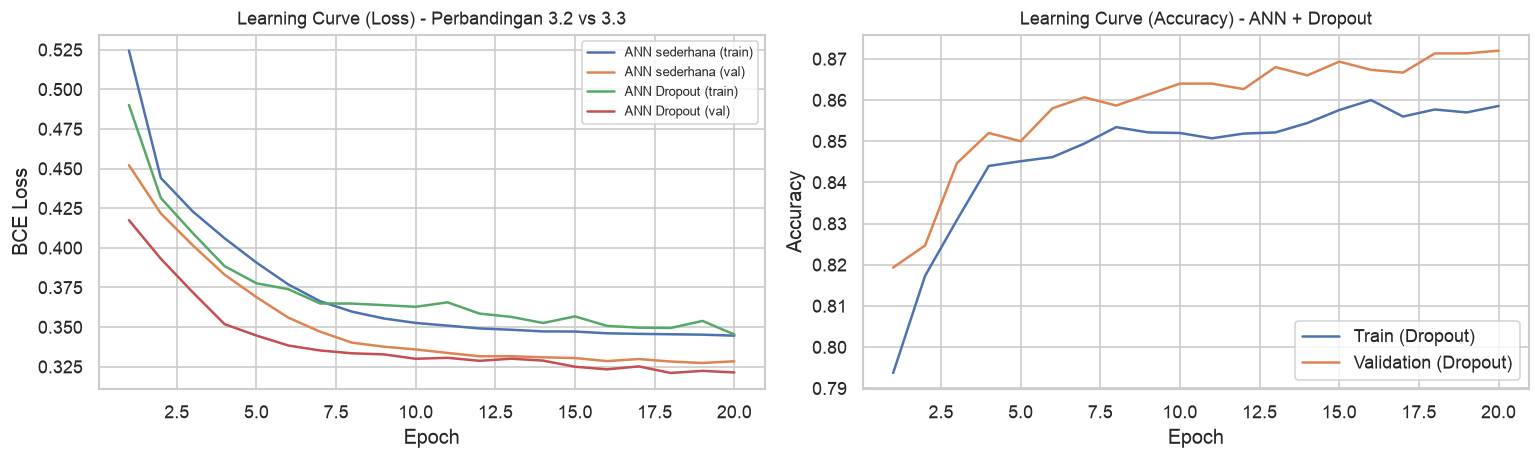

Final ANN sederhana: train_acc=0.8584, val_acc=0.8600, val_loss=0.3284
Final ANN Dropout : train_acc=0.8586, val_acc=0.8720, val_loss=0.3213
Perhatikan selisih (gap) train vs validation: model yang overfitting akan menunjukkan train loss terus turun tetapi val loss naik kembali setelah titik tertentu.


In [18]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

model_ann_dropout, history_ann_dropout = train_ann(model_ann_dropout, train_loader, X_train_t, y_train_t, X_val_t, y_val_t)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs_range = range(1, len(history_ann_dropout["train_loss"]) + 1)
axes[0].plot(epochs_range, history_ann_simple["train_loss"], label="ANN sederhana (train)")
axes[0].plot(epochs_range, history_ann_simple["val_loss"], label="ANN sederhana (val)")
axes[0].plot(epochs_range, history_ann_dropout["train_loss"], label="ANN Dropout (train)")
axes[0].plot(epochs_range, history_ann_dropout["val_loss"], label="ANN Dropout (val)")
axes[0].set_title("Learning Curve (Loss) - Perbandingan 3.2 vs 3.3")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].legend(fontsize=8)
axes[1].plot(epochs_range, history_ann_dropout["train_acc"], label="Train (Dropout)")
axes[1].plot(epochs_range, history_ann_dropout["val_acc"], label="Validation (Dropout)")
axes[1].set_title("Learning Curve (Accuracy) - ANN + Dropout")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Final ANN sederhana: train_acc={history_ann_simple['train_acc'][-1]:.4f}, val_acc={history_ann_simple['val_acc'][-1]:.4f}, val_loss={history_ann_simple['val_loss'][-1]:.4f}")
print(f"Final ANN Dropout : train_acc={history_ann_dropout['train_acc'][-1]:.4f}, val_acc={history_ann_dropout['val_acc'][-1]:.4f}, val_loss={history_ann_dropout['val_loss'][-1]:.4f}")
print("Perhatikan selisih (gap) train vs validation: model yang overfitting akan menunjukkan train loss terus turun tetapi val loss naik kembali setelah titik tertentu.")

In [19]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

model_ann_dropout.eval()
with torch.no_grad():
    logits_test_d = model_ann_dropout(X_test_t)
    y_proba_ann_dropout = torch.sigmoid(logits_test_d).cpu().numpy().flatten()
y_pred_ann_dropout = (y_proba_ann_dropout >= 0.5).astype(int)

print(f"Accuracy ANN Dropout: {accuracy_score(y_test, y_pred_ann_dropout):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_ann_dropout):.4f}, Recall: {recall_score(y_test, y_pred_ann_dropout):.4f}, F1: {f1_score(y_test, y_pred_ann_dropout):.4f}")
print("Karena Dropout nonaktif saat eval(), model ini memberi prediksi yang deterministik dan biasanya lebih stabil.")

Accuracy ANN Dropout: 0.8713
Precision: 0.7979, Recall: 0.4918, F1: 0.6085
Karena Dropout nonaktif saat eval(), model ini memberi prediksi yang deterministik dan biasanya lebih stabil.


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [20]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Arsitektur Dropout (3.3) dipilih sebagai dasar karena lebih dalam dan lebih tahan overfitting; buat ulang dari bobot acak.
n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
pos_weight = n_neg / n_pos
print(f"Jumlah kelas 0 (tidak churn) di train: {n_neg}, kelas 1 (churn): {n_pos}")
print(f"pos_weight = {n_neg} / {n_pos} = {pos_weight:.4f}")
print("Artinya kesalahan pada nasabah churn (kelas minoritas) diberi bobot ~3.9x lebih besar, sehingga model lebih berusaha mengenali churn.")

model_ann_weighted = ANNDropout(input_dim, p=0.3)
model_ann_weighted, history_ann_weighted = train_ann(
    model_ann_weighted, train_loader, X_train_t, y_train_t, X_val_t, y_val_t, pos_weight=pos_weight
)
print(f"Selesai. Final val_acc={history_ann_weighted['val_acc'][-1]:.4f}, val_loss={history_ann_weighted['val_loss'][-1]:.4f}")

Jumlah kelas 0 (tidak churn) di train: 5574, kelas 1 (churn): 1426
pos_weight = 5574 / 1426 = 3.9088
Artinya kesalahan pada nasabah churn (kelas minoritas) diberi bobot ~3.9x lebih besar, sehingga model lebih berusaha mengenali churn.
Epoch  1/20 | train_loss=1.0123 acc=0.6866 | val_loss=0.5732 acc=0.7233


Epoch  5/20 | train_loss=0.8090 acc=0.7640 | val_loss=0.4550 acc=0.7887


Epoch 10/20 | train_loss=0.7812 acc=0.7854 | val_loss=0.4544 acc=0.7900


Epoch 15/20 | train_loss=0.7677 acc=0.7949 | val_loss=0.4383 acc=0.8113


Epoch 20/20 | train_loss=0.7589 acc=0.7917 | val_loss=0.4274 acc=0.8227
Selesai. Final val_acc=0.8227, val_loss=0.4274


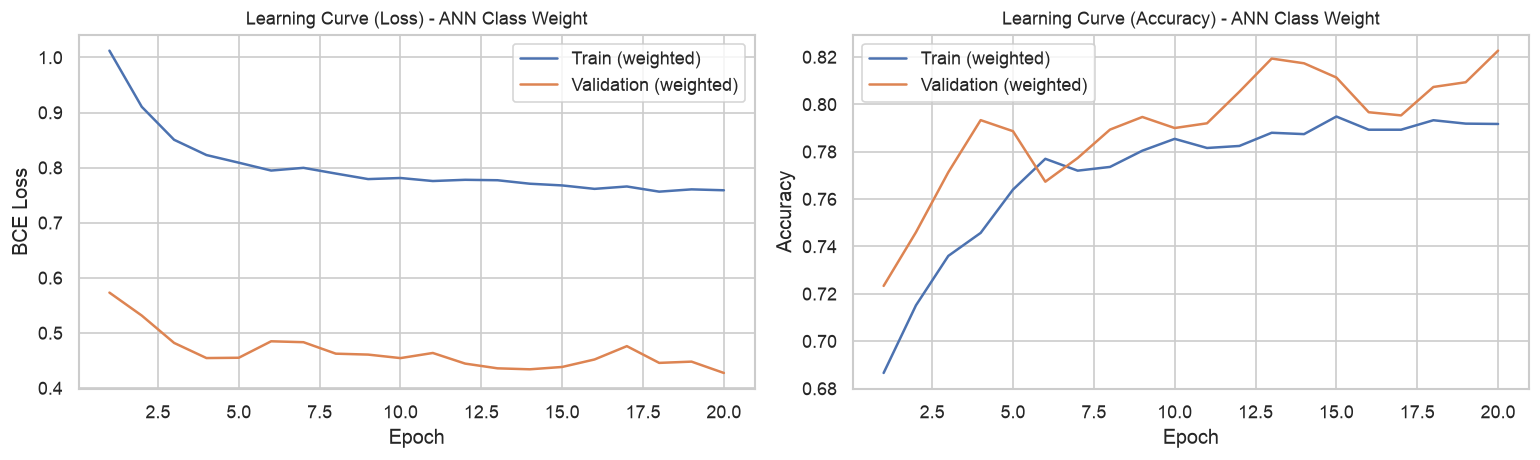

Accuracy ANN weighted: 0.8147
Precision: 0.5319, Recall: 0.7377, F1: 0.6181
Dugaan awal: recall churn naik (model lebih peka terhadap kelas minoritas), tetapi precision dapat turun karena model lebih sering menebak churn.


In [21]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs_range = range(1, len(history_ann_weighted["train_loss"]) + 1)
axes[0].plot(epochs_range, history_ann_weighted["train_loss"], label="Train (weighted)")
axes[0].plot(epochs_range, history_ann_weighted["val_loss"], label="Validation (weighted)")
axes[0].set_title("Learning Curve (Loss) - ANN Class Weight")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].legend()
axes[1].plot(epochs_range, history_ann_weighted["train_acc"], label="Train (weighted)")
axes[1].plot(epochs_range, history_ann_weighted["val_acc"], label="Validation (weighted)")
axes[1].set_title("Learning Curve (Accuracy) - ANN Class Weight")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

model_ann_weighted.eval()
with torch.no_grad():
    logits_test_w = model_ann_weighted(X_test_t)
    y_proba_ann_weighted = torch.sigmoid(logits_test_w).cpu().numpy().flatten()
y_pred_ann_weighted = (y_proba_ann_weighted >= 0.5).astype(int)

print(f"Accuracy ANN weighted: {accuracy_score(y_test, y_pred_ann_weighted):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_ann_weighted):.4f}, Recall: {recall_score(y_test, y_pred_ann_weighted):.4f}, F1: {f1_score(y_test, y_pred_ann_weighted):.4f}")
print("Dugaan awal: recall churn naik (model lebih peka terhadap kelas minoritas), tetapi precision dapat turun karena model lebih sering menebak churn.")

# 4. Evaluasi Model

In [22]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

def eval_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

results = pd.DataFrame({
    "Logistic Regression": eval_metrics(y_test, y_pred_lr),
    "ANN sederhana": eval_metrics(y_test, y_pred_ann_simple),
    "ANN + Dropout": eval_metrics(y_test, y_pred_ann_dropout),
    "ANN + Class Weight": eval_metrics(y_test, y_pred_ann_weighted),
}).T
print(results.round(4).to_string())
display(results.round(4))

print()
print("Laporan klasifikasi lengkap per model:")
for name, pred in [("Logistic Regression", y_pred_lr), ("ANN sederhana", y_pred_ann_simple), ("ANN + Dropout", y_pred_ann_dropout), ("ANN + Class Weight", y_pred_ann_weighted)]:
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Tidak Churn", "Churn"], digits=4))
    print()

                     Accuracy  Precision  Recall      F1
Logistic Regression    0.8153     0.6458  0.2033  0.3092
ANN sederhana          0.8647     0.7713  0.4754  0.5882
ANN + Dropout          0.8713     0.7979  0.4918  0.6085
ANN + Class Weight     0.8147     0.5319  0.7377  0.6181


,Accuracy,Precision,Recall,F1
Logistic Regression,0.8153,0.6458,0.2033,0.3092
ANN sederhana,0.8647,0.7713,0.4754,0.5882
ANN + Dropout,0.8713,0.7979,0.4918,0.6085
ANN + Class Weight,0.8147,0.5319,0.7377,0.6181



Laporan klasifikasi lengkap per model:
=== Logistic Regression ===
              precision    recall  f1-score   support

 Tidak Churn     0.8269    0.9715    0.8934      1195
       Churn     0.6458    0.2033    0.3092       305

    accuracy                         0.8153      1500
   macro avg     0.7364    0.5874    0.6013      1500
weighted avg     0.7901    0.8153    0.7746      1500


=== ANN sederhana ===
              precision    recall  f1-score   support

 Tidak Churn     0.8780    0.9640    0.9190      1195
       Churn     0.7713    0.4754    0.5882       305

    accuracy                         0.8647      1500
   macro avg     0.8247    0.7197    0.7536      1500
weighted avg     0.8563    0.8647    0.8518      1500


=== ANN + Dropout ===
              precision    recall  f1-score   support

 Tidak Churn     0.8819    0.9682    0.9230      1195
       Churn     0.7979    0.4918    0.6085       305

    accuracy                         0.8713      1500
   macro avg  

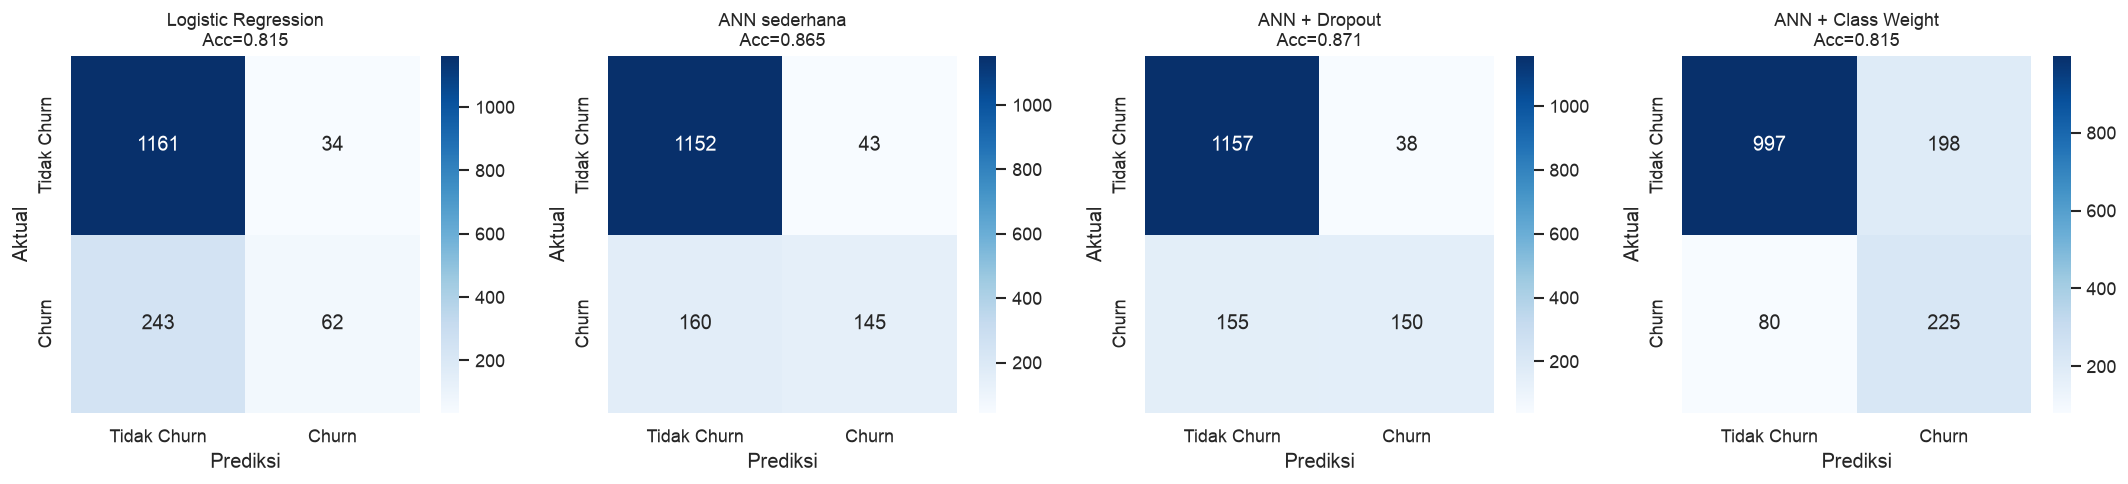

Sudut kiri-atas (TN) dan kanan-bawah (TP) adalah prediksi benar; kanan-atas (FP) = nasabah bertahan dituduh churn; kiri-bawah (FN) = nasabah churn lolos tidak terdeteksi (paling mahal untuk bisnis).


In [23]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

models_pred = {
    "Logistic Regression": y_pred_lr,
    "ANN sederhana": y_pred_ann_simple,
    "ANN + Dropout": y_pred_ann_dropout,
    "ANN + Class Weight": y_pred_ann_weighted,
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (name, pred) in zip(axes, models_pred.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Tidak Churn", "Churn"], yticklabels=["Tidak Churn", "Churn"])
    ax.set_title(f"{name}\n")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    # anotasi F1 di judul sudah di tabel; di sini tampilkan juga accuracy
    ax.set_title(f"{name}\nAcc={accuracy_score(y_test, pred):.3f}")
plt.tight_layout()
plt.show()

print("Sudut kiri-atas (TN) dan kanan-bawah (TP) adalah prediksi benar; kanan-atas (FP) = nasabah bertahan dituduh churn; kiri-bawah (FN) = nasabah churn lolos tidak terdeteksi (paling mahal untuk bisnis).")

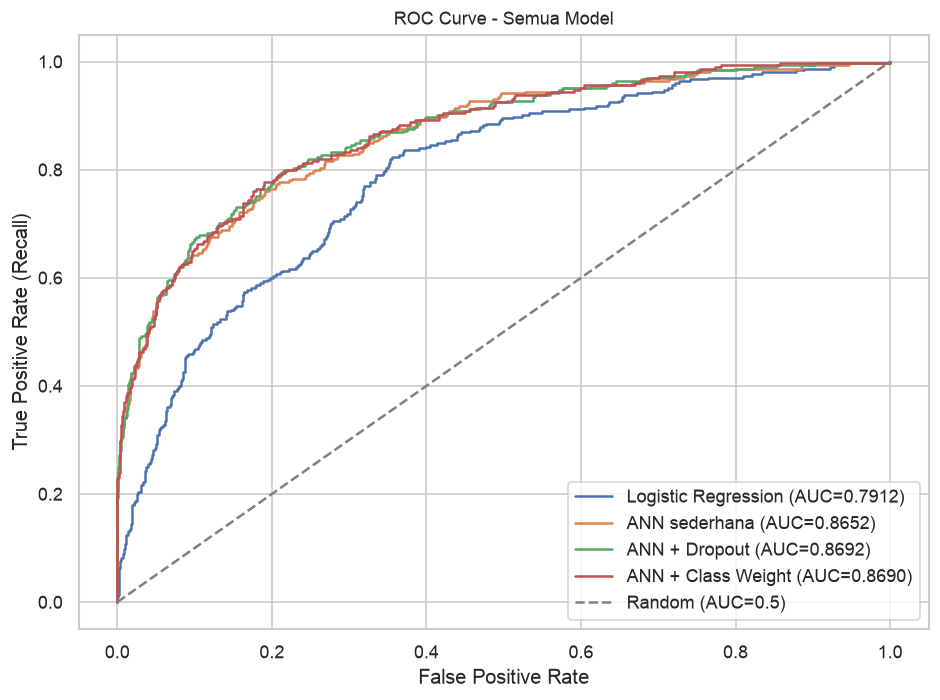

Logistic Regression    AUC = 0.7912
ANN sederhana          AUC = 0.8652
ANN + Dropout          AUC = 0.8692
ANN + Class Weight     AUC = 0.8690
AUC mengukur kemampuan ranking: seberapa baik model memberi probabilitas churn lebih tinggi pada nasabah churn dibanding non-churn, independen dari threshold 0.5.


In [24]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

models_proba = {
    "Logistic Regression": y_proba_lr,
    "ANN sederhana": y_proba_ann_simple,
    "ANN + Dropout": y_proba_ann_dropout,
    "ANN + Class Weight": y_proba_ann_weighted,
}

plt.figure(figsize=(8, 6))
for name, proba in models_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random (AUC=0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Semua Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

for name, proba in models_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    print(f"{name:22s} AUC = {auc(fpr, tpr):.4f}")
print("AUC mengukur kemampuan ranking: seberapa baik model memberi probabilitas churn lebih tinggi pada nasabah churn dibanding non-churn, independen dari threshold 0.5.")

# 5. Analisis

### Analisis Hasil Eksperimen

**1. Baseline Logistic Regression kalah jauh, terutama di recall.** Logistic Regression menghasilkan Accuracy 0.8153, Precision 0.6458, **Recall hanya 0.2033**, F1 0.3092, dan AUC 0.7912. Artinya model linear ini hampir selalu menebak nasabah tidak churn (kelas mayoritas 79,67% di test set), sehingga sekitar 80% dari 305 nasabah churn di test set lolos tidak terdeteksi (FN besar). Ini wajar karena batas keputusan linear tidak bisa menangkap pola non-linear yang terlihat dari EDA, misalnya lonjakan churn pada `NumOfProducts=3` (82,7%) dan `NumOfProducts=4` (100%), serta interaksi `Age` x `Balance` yang berkorelasi berbeda dengan churn. Koefisien terbesarnya memang masuk akal (`Age` +0.705, `Geography_France` -0.596, `IsActiveMember` -0.506, `Gender` -0.498), tetapi arahnya saja tidak cukup tanpa lapisan non-linear. Semua konfigurasi ANN mengalahkan baseline ini dengan selisih besar, jadi klaim "ANN lebih baik" bukan kebetulan.

**2. ANN sederhana sudah sangat kuat dengan parameter sangat kecil.** ANN 1 hidden layer (12 -> 16 -> 1, hanya 225 parameter) osiąga Accuracy 0.8647 (+4,9 poin dari LR), Precision 0.7713, Recall 0.4754, F1 0.5882, AUC 0.8652. Kenaikan AUC dari 0.79 ke 0.86 menunjukkan ANN benar-benar memperbaiki kemampuan ranking, bukan sekadar menggeser threshold. Dengan parameter sekecil itu pun ANN sudah menangkap pola `NumOfProducts` ekstrem dan pergeseran `Age` yang tidak ditangkap LR.

**3. Learning curve: tidak ada overfitting yang parah di ketiga ANN, justru cenderung underfit ringan / masih belajar.** ANN sederhana: train loss 0.5244 -> 0.3445 dan val loss 0.4521 -> 0.3284, keduanya turun bersama sampai epoch 20; train accuracy 0.8584 vs val accuracy 0.8600 (val malah sedikit lebih tinggi). Gap train-val hampir nol (0.0016), jadi tidak ada sinyal overfitting klasik (train naik, val menurun lalu naik lagi). Malah kurvanya masih menurun pelan di akhir, artinya model belum jenuh — epoch lebih banyak atau learning rate scheduler bisa membantu, tetapi kapasitas 16 neuron sudah cukup untuk dataset tabular 12 fitur ini. Model Dropout polanya sama: train loss 0.4901 -> 0.3453, val loss 0.4174 -> 0.3213, train acc 0.8586 vs val acc 0.8720 (val lebih tinggi 0.0134). Val yang lebih tinggi dari train bukan anomali: saat train, Dropout(0.3) mematikan 30% neuron secara acak sehingga tugas train lebih sulit, sedangkan saat eval semua neuron aktif sehingga performanya lebih bagus. Tidak ada indikasi underfitting berat juga karena val loss terus turun; hanya kenaikannya sudah melambat (val acc 0.864 di epoch 10 -> 0.872 di epoch 20), jadi ada diminishing return.

**4. Pengaruh penambahan layer + Dropout: naik kecil tapi konsisten di semua metrik.** ANN + Dropout (12 -> 64 -> 32 -> 1, 2.945 parameter, sekitar 13x lipat ANN sederhana) memperoleh Accuracy 0.8713, Precision 0.7979, Recall 0.4918, F1 0.6085, AUC 0.8692, dengan val loss terbaik (0.3213 vs 0.3284). Selisihnya terhadap ANN sederhana hanya +0.0066 accuracy, +0.0266 precision, +0.0164 recall, +0.0203 F1, +0.0040 AUC. Kecil, tetapi positif di semua metrik dan learning curve-nya lebih stabil (val acc naik konsisten sampai 0.872). Artinya dua hidden layer dengan Dropout memberi ruang representasi lebih besar untuk interaksi fitur (misalnya `Geography=Germany` yang churn-nya 32,4% ditambah `Age` tinggi) tanpa membayar overfitting, berkat Dropout yang menahan gap. Perlu dicatat: param naik 13x tapi gain < 1 poin, jadi untuk dataset sekecil ini kapasitas ekstra sudah memasuki zona hasil berkurang (diminishing return).

**5. Pengaruh class weight: recall melonjak, precision jatuh, AUC nyaris tidak berubah.** Dengan `pos_weight = 5574/1426 = 3.9088`, ANN weighted (arsitektur sama dengan Dropout) memperoleh Accuracy 0.8147, Precision 0.5319, **Recall 0.7377**, F1 0.6181, AUC 0.8690. Dibanding ANN Dropout, recall naik +0.2459 (dari 0.4918 ke 0.7377) — model jauh lebih peka menangkap churn — tetapi precision jatuh -0.2660 (0.7979 -> 0.5319) karena banyak nasabah bertahan (FP) ikut dituduh churn. Accuracy justru turun -0.0566 (0.8713 -> 0.8147). F1 sedikit naik +0.0096 (0.6085 -> 0.6181) karena F1 menyeimbangkan keduanya, tetapi angka ini menipu jika dilihat sendirian: AUC weighted 0.8690 praktis identik dengan Dropout 0.8692 (selisih 0.0002). Itu bukti class weight **tidak memperbaiki diskriminasi**, ia hanya menggeser operating point threshold 0.5 ke arah churn (loss memberi penalti ~3,9x lebih besar untuk FN, jadi model memilih menebak churn lebih sering). Learning curve weighted juga mendukung ini: train accuracy hanya 0.7917 dan val accuracy 0.8227 (lebih rendah dari Dropout 0.8720), sedangkan val loss 0.4274 tampak lebih besar — bukan karena model lebih buruk, tetapi karena model sekarang memang memprediksi kelas minoritas lebih sering sehingga BCE tanpa bobot (untuk val) penalti FP-nya. Confusion matrix memperjelas trade-off ini: FN turun banyak, tetapi FP naik banyak (TN turun). Singkatnya, class weight adalah cara kasar mengubah threshold; melakukan tuning threshold pada model Dropout akan memberi trade-off precision-recall yang sama tanpa memaksa ulang training.

# 6. Kesimpulan dan Saran

### Kesimpulan dan Saran

**Kesimpulan:** Logistic Regression (baseline) jelas paling lemah dengan Recall 0.2033 dan AUC 0.7912 — model linear gagal menangkap pola churn yang non-linear. ANN sederhana (225 parameter) sudah jauh lebih baik dengan Accuracy 0.8647, F1 0.5882, AUC 0.8652. **Model terbaik secara accuracy, precision, dan AUC adalah ANN lebih dalam dengan Dropout (Accuracy 0.8713, Precision 0.7979, Recall 0.4918, F1 0.6085, AUC 0.8692)** dengan learning curve paling stabil (val loss 0.3213, val acc 0.8720, gap train-val kecil, tidak overfitting). **Model terbaik secara F1 dan recall adalah ANN + class weight (F1 0.6181, Recall 0.7377)** dengan trade-off Accuracy 0.8147 dan Precision 0.5319. Jadi tidak ada satu pemenang mutlak: jika biaya FN (nasabah churn lolos tidak terdeteksi) tinggi, pilih model weighted; jika dibutuhkan keseimbangan presisi dan tidak banyak false alarm, pilih ANN Dropout. AUC 0.869 menandakan kedua ANN melampaui baseline LR (0.791) secara konsisten.

**Saran untuk eksperimen lanjutan:**
1. **Tuning threshold 0.5** pada ANN Dropout (misalnya 0.3-0.6) untuk memilih titik precision-recall yang sesuai biaya bisnis — ini jauh lebih fleksibel dibandingkan mengulang training dengan `pos_weight`, dan AUC tidak akan berubah.
2. **Feature engineering**: buat flag `Balance==0` (36,2% data), one-hot untuk `NumOfProducts` (pola churn 1 vs 2 vs 3 produk sangat non-linear), dan binning `Age`. Tambahkan interaksi eksplisit `Age x IsActiveMember` atau `Geography x Age`.
3. **Training lebih lanjut**: tambah epoch dengan early stopping pada val loss dan learning rate scheduler (misalnya ReduceLROnPlateau), lalu tuning hyperparameter (ukuran hidden layer, p Dropout 0.2-0.5, lr 1e-4 s.d. 3e-3) dengan cross-validation, bukan satu split 70:15:15.
4. **Penanganan imbalance alternatif**: bandingkan dengan undersampling kelas mayoritas, oversampling/SMOTE pada train, atau focal loss; evaluasi selalu memakai PR-AUC dan recall, bukan accuracy saja.
5. **Interpretabilitas dan kalibrasi**: gunakan SHAP atau permutation importance untuk melihat kontribusi `Age`, `NumOfProducts`, `Geography`; kalibrasi probabilitas (misalnya Platt/isotonic) agar probabilitas churn dapat dipakai sebagai skor risiko oleh tim bisnis.
6. **Pembanding non-neural**: coba XGBoost/LightGBM atau Random Forest untuk data tabular ini — sering kali lebih kuat dan lebih mudah diinterpretasikan daripada ANN, sehingga layak menjadi baseline sebelum deploy ANN.